# Lab 2 — Autoencoders as PCA and Multivariate Representations for Clustering

**Can a neural network discover the same underlying multivariate structure as PCA, and can its latent representation help identify natural groupings in the data?**

### Learning objectives
1. Explain why a linear autoencoder trained on centered data with squared-error loss can recover the same **principal subspace** as PCA.
2. Distinguish PCA coordinates from autoencoder latent coordinates (which can be rotated or rescaled).
3. Compare low-dimensional reconstruction errors.
4. Use K-means to cluster original features, PCA scores, and autoencoder embeddings.
5. Explain why *good reconstruction*, *good visualization*, and *good clustering* are different objectives.

> **Important:** This is not a claim that autoencoders optimize clusters. An unsupervised autoencoder "minimizes reconstruction error", not within-cluster distances.

## Part 1 — Generate multivariate data with known group structure
We simulate **four groups** in an underlying two-dimensional space, mix them into **12 observed variables**, and add measurement noise. The group labels are retained only for **evaluation**, not for fitting PCA, the autoencoders, or K-means.

This resembles multivariate experimental measurements (e.g., correlated traits or metabolomic features) with an underlying low-dimensional structure.

X shape: (1000, 12) | group sizes: [250 250 250 250]
Max absolute feature mean after scaling: 0.0


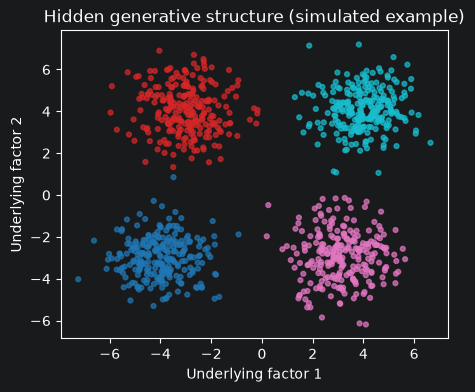

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score, mean_squared_error
from scipy.linalg import subspace_angles

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)  # reasonable CPU usage in a classroom

n_samples, n_features, n_clusters, latent_dim = 1000, 12, 4, 2
z_true, true_group = make_blobs(
    n_samples=n_samples, centers=[(-4,-3), (-3,4), (3,-3), (4,4)],
    cluster_std=[1.0, 1.1, 1.1, 1.0], random_state=SEED
)
# Orthonormal mixing from 2 dimensions into 12 observed variables.
mix, _ = np.linalg.qr(rng.normal(size=(n_features, latent_dim)))
X_observed = z_true @ mix.T + rng.normal(scale=0.20, size=(n_samples, n_features))
X = StandardScaler().fit_transform(X_observed).astype('float32')
print('X shape:', X.shape, '| group sizes:', np.bincount(true_group))
print('Max absolute feature mean after scaling:', np.abs(X.mean(axis=0)).max().round(6))

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(z_true[:,0], z_true[:,1], c=true_group, s=12, cmap='tab10', alpha=.7)
ax.set(title='Hidden generative structure (simulated example)', xlabel='Underlying factor 1', ylabel='Underlying factor 2')
plt.show()

### Question 1
If the data have 12 measured variables but only 2 underlying factors, what dimensionality would you expect PCA to recover? What changes when noise increases?

## Part 2 — PCA benchmark
PCA produces orthogonal axes. For centered data and an appropriately chosen rank, it minimizes squared reconstruction error among **linear rank-constrained reconstructions**.



Explained variance per component: [0.619 0.355]
Total explained variance: 0.974
PCA reconstruction MSE: 0.02646


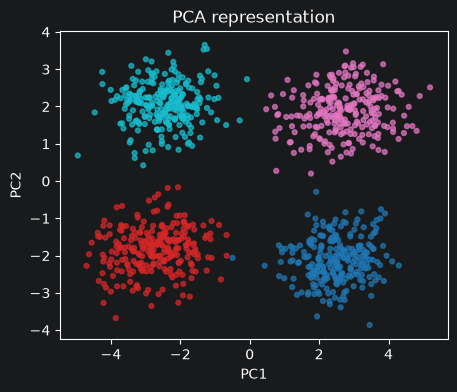

In [4]:
pca = PCA(n_components=latent_dim)
Z_pca = pca.fit_transform(X)
X_pca = pca.inverse_transform(Z_pca)

print('Explained variance per component:', np.round(pca.explained_variance_ratio_, 3))
print('Total explained variance:', round(sum(pca.explained_variance_ratio_), 3))
print('PCA reconstruction MSE:', round(mean_squared_error(X, X_pca), 5))

fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(Z_pca[:,0], Z_pca[:,1], c=true_group, s=12, cmap='tab10', alpha=.7)
ax.set(title='PCA representation', xlabel='PC1', ylabel='PC2')
plt.show()

## Part 3 — Train a strictly linear autoencoder

An encoder and decoder with **no activation functions**, **no biases**, and a two-dimensional bottleneck:

\\[
\mathbf{z} = W_e \mathbf{x},\qquad \hat{\mathbf{x}} = W_d\mathbf{z}
\\]

For centered data with MSE loss, the best achievable reconstruction lies in the **same top-two principal subspace** as PCA (assuming a suitable rank and convergence). **The latent coordinates themselves need not equal PC1 and PC2.**

In [5]:
class LinearAE(nn.Module):
    def __init__(self, input_dim, code_dim=2):
        super().__init__()
        self.encoder = nn.Linear(input_dim, code_dim, bias=False)
        self.decoder = nn.Linear(code_dim, input_dim, bias=False)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


def train_ae(model, X_np, epochs=500, lr=0.02, log_every=100):
    X_tensor = torch.as_tensor(X_np, dtype=torch.float32)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    model.train()
    for epoch in range(1, epochs+1):
        optimizer.zero_grad()
        reconstruction = model(X_tensor)
        loss = torch.mean((reconstruction - X_tensor)**2)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
        if log_every and epoch % log_every == 0:
            print(f'Epoch {epoch:>4}: MSE={loss.item():.6f}')
    model.eval()
    return np.array(history)

linear_ae = LinearAE(n_features, latent_dim)
loss_linear = train_ae(linear_ae, X, epochs=500, lr=0.02)
with torch.no_grad():
    Z_linear = linear_ae.encoder(torch.tensor(X)).numpy()
    X_linear = linear_ae(torch.tensor(X)).numpy()
print('Linear AE reconstruction MSE:', round(mean_squared_error(X, X_linear), 5))

Epoch  100: MSE=0.027669
Epoch  200: MSE=0.026697
Epoch  300: MSE=0.026573
Epoch  400: MSE=0.026510
Epoch  500: MSE=0.026480
Linear AE reconstruction MSE: 0.02648


## Part 4 — Verify the PCA analogy correctly

We compare **reconstruction error** and **principal angles between subspaces**, not whether PC1 and `z1` look identical. The optimal linear AE may represent the same subspace with different coordinates.

Principal angles between PCA and linear-AE decoder subspaces (degrees): [0.023 0.001]


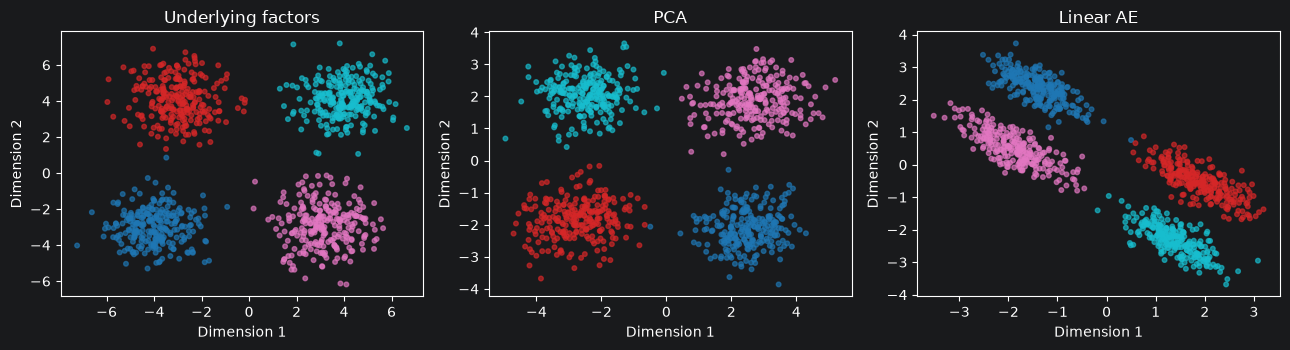

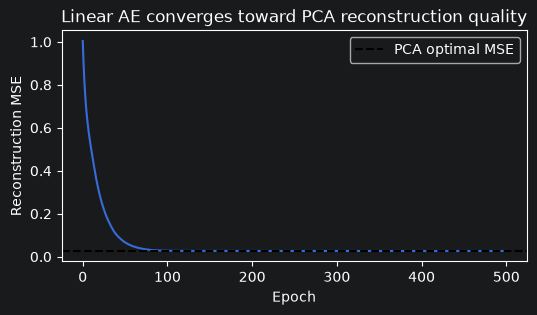

In [6]:
# Columns of these matrices span the reconstructed subspaces in feature space.
pca_basis = pca.components_.T
with torch.no_grad():
    decoder_basis = linear_ae.decoder.weight.detach().numpy()
angles_deg = np.degrees(subspace_angles(pca_basis, decoder_basis))
print('Principal angles between PCA and linear-AE decoder subspaces (degrees):', np.round(angles_deg, 3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, coords, title in zip(axes, [z_true, Z_pca, Z_linear], ['Underlying factors', 'PCA', 'Linear AE']):
    ax.scatter(coords[:,0], coords[:,1], c=true_group, s=11, cmap='tab10', alpha=.65)
    ax.set(title=title, xlabel='Dimension 1', ylabel='Dimension 2')
plt.tight_layout(); plt.show()

plt.figure(figsize=(6,3))
plt.plot(loss_linear)
plt.axhline(mean_squared_error(X, X_pca), ls='--', c='black', label='PCA optimal MSE')
plt.xlabel('Epoch'); plt.ylabel('Reconstruction MSE'); plt.legend(); plt.title('Linear AE converges toward PCA reconstruction quality')
plt.show()

### Question 2
Why might the scatterplot of the linear AE appear rotated or stretched relative to PCA, even if the two models have nearly identical reconstruction errors?

### Key Points
- **PCA scores ≠ raw AE codes** in general: the AE code basis may rotate, reflect, scale, or shear.
- **Clustering ≠ representation learning**: K-means imposes a different objective then AE; clusters in a plot require independent validation.


## Part 5 — Train a nonlinear autoencoder

Nonlinear transformations permit more flexible low-dimensional embeddings. But extra flexibility **does not guarantee** better clustering, interpretability, or generalization. Because our simulated data are mostly linear, PCA is already a strong baseline.

Epoch  100: MSE=0.027643
Epoch  200: MSE=0.026627
Epoch  300: MSE=0.026392
Epoch  400: MSE=0.026255
Epoch  500: MSE=0.026182
Nonlinear AE training reconstruction MSE: 0.02618


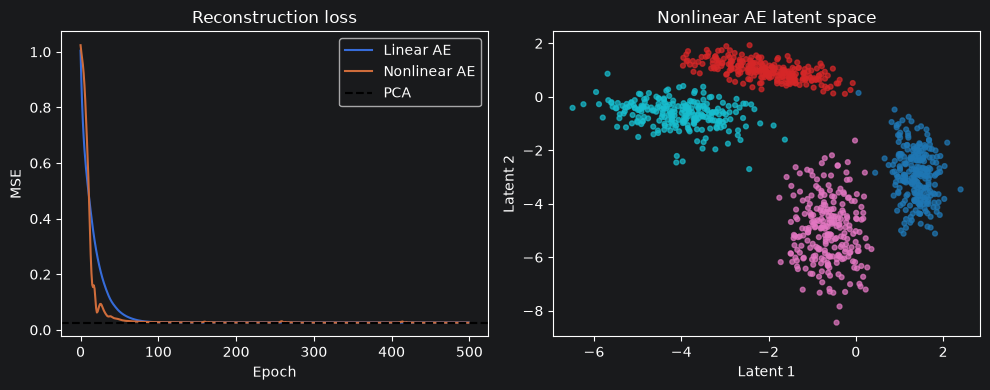

In [7]:
class NonlinearAE(nn.Module):
    def __init__(self, input_dim, code_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, 32), nn.ReLU(),
                                     nn.Linear(32, 16), nn.ReLU(),
                                     nn.Linear(16, code_dim))
        self.decoder = nn.Sequential(nn.Linear(code_dim, 16), nn.ReLU(),
                                     nn.Linear(16, 32), nn.ReLU(),
                                     nn.Linear(32, input_dim))

    def forward(self, x):
        return self.decoder(self.encoder(x))

nonlinear_ae = NonlinearAE(n_features, latent_dim)
loss_nonlinear = train_ae(nonlinear_ae, X, epochs=500, lr=0.01)
with torch.no_grad():
    Z_nonlinear = nonlinear_ae.encoder(torch.tensor(X)).numpy()
    X_nonlinear = nonlinear_ae(torch.tensor(X)).numpy()
print('Nonlinear AE training reconstruction MSE:', round(mean_squared_error(X, X_nonlinear), 5))

fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].plot(loss_linear, label='Linear AE')
axes[0].plot(loss_nonlinear, label='Nonlinear AE')
axes[0].axhline(mean_squared_error(X, X_pca), c='black', ls='--', label='PCA')
axes[0].legend(); axes[0].set(title='Reconstruction loss', xlabel='Epoch', ylabel='MSE')
axes[1].scatter(Z_nonlinear[:,0], Z_nonlinear[:,1], c=true_group, s=12, cmap='tab10', alpha=.7)
axes[1].set(title='Nonlinear AE latent space', xlabel='Latent 1', ylabel='Latent 2')
plt.tight_layout();plt.show()

## Part 6 — Perform the same clustering in four representations

Apply **K-means** to (1) all measured features, (2) PCA scores, (3) linear AE codes, and (4) nonlinear AE codes. To compare K-means fairly, we use fixed initializations and a fixed number of clusters.

- **Adjusted Rand Index (ARI):** agreement with held-out *known synthetic group labels* (1 = perfect; 0 ≈ random agreement).
- **Silhouette score:** separation/compactness **within each representation**. Because its geometry and dimensionality vary across representations, it should not be read as an absolute measure of biological correctness.
- Reconstruction error evaluates retained feature information; it **does not directly measure clustering quality**.

 Representation  Dimension  ARI vs known groups  Silhouette (own space)
   Original 12D         12                0.997                   0.626
         PCA 2D          2                0.997                   0.685
   Linear AE 2D          2                0.984                   0.576
Nonlinear AE 2D          2                0.915                   0.566


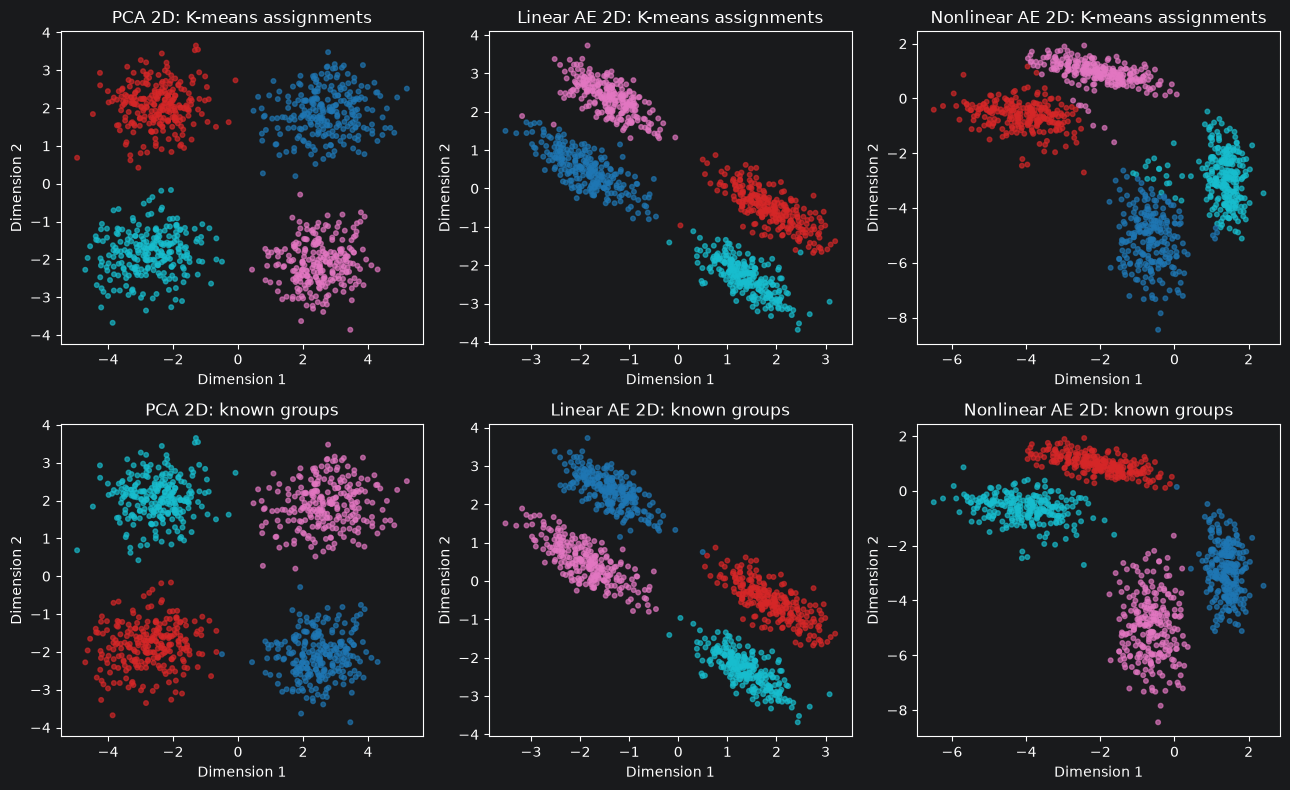

In [8]:
representations = {
    'Original 12D': X,
    'PCA 2D': Z_pca,
    'Linear AE 2D': Z_linear,
    'Nonlinear AE 2D': Z_nonlinear,
}
cluster_assignments = {}
rows = []
for name, embedding in representations.items():
    clustering = KMeans(n_clusters=n_clusters, random_state=SEED, n_init=20)
    labels = clustering.fit_predict(embedding)
    cluster_assignments[name] = labels
    rows.append({
        'Representation': name,
        'Dimension': embedding.shape[1],
        'ARI vs known groups': adjusted_rand_score(true_group, labels),
        'Silhouette (own space)': silhouette_score(embedding, labels),
    })
results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, coords) in zip(axes.flat, list(representations.items())[1:]):
    ax.scatter(coords[:,0], coords[:,1], c=cluster_assignments[name], s=11, cmap='tab10', alpha=.65)
    ax.set(title=f'{name}: K-means assignments', xlabel='Dimension 1', ylabel='Dimension 2')
for ax, (name, coords) in zip(axes.flat[3:], list(representations.items())[1:]):
    ax.scatter(coords[:,0], coords[:,1], c=true_group, s=11, cmap='tab10', alpha=.65)
    ax.set(title=f'{name}: known groups', xlabel='Dimension 1', ylabel='Dimension 2')
plt.tight_layout(); plt.show()

### Question 3
Which representation leads to the highest ARI? Is it also the representation with the lowest reconstruction MSE? Explain why these results need not agree.

### Question 4
PCA and the AE use *no group labels* during fitting. Are the colors in the latent scatterplots evidence of supervised learning? Why or why not?

### Key Points
- **Nonlinearity adds flexibility**, with potential benefits on curved data and risks of overfitting or distorted distances.
- **Synthetic known labels are an evaluation aid**. On real experimental data, clusters may be absent, continuous, or confounded by batch, environment, or sampling.

## Part 7 — An optional nonlinear challenge
Construct a dataset with nonlinear features from two continuous variables. Re-run PCA, the linear AE, and nonlinear AE, then evaluate **reconstruction** first. A nonlinear mapping may outperform a linear rank-two model, but it does not necessarily recover a uniquely interpretable intrinsic coordinate system.

In [9]:
# Optional: replace X in the training cells with X_curved and re-run Parts 2–6.
t = rng.uniform(-2.5, 2.5, 1000)
u = rng.uniform(-2, 2, 1000)
nonlinear_features = np.column_stack([
    t, u, t**2, u**2, t*u, np.sin(2*t), np.cos(2*t),
    np.sin(2*u), np.cos(2*u), np.sin(t+u), np.exp(-t**2), np.exp(-u**2)
])
X_curved = StandardScaler().fit_transform(
    nonlinear_features + rng.normal(scale=0.08, size=nonlinear_features.shape)
).astype('float32')
print('Curved data shape:', X_curved.shape)
print('Task: substitute X = X_curved, retrain, and compare reconstruction errors.')
print('Note: the original true_group labels do not apply to this separate dataset.')

Curved data shape: (1000, 12)
Task: substitute X = X_curved, retrain, and compare reconstruction errors.
Note: the original true_group labels do not apply to this separate dataset.


## Part 8 — Guided exploration

Try **one manipulation at a time**:

1. Increase the *observation noise from `0.20` to `0.80`* ( Cell 1 Line 26).
    - How do explained variance and ARI change?
2. Change the bottleneck from 2 to 1 (update PCA and both AEs `code_dim`).
    - Which group differences are lost?
3. Increase the bottleneck from 2 to 4.
    - What happens to MSE?
    - Does cluster quality always improve?
4. Train the nonlinear AE with different random seeds(`SEED = 42`).
    - How stable are the latent coordinates and assignments?
5. Repeat the nonlinear challenge using `X_curved`; report PCA and AE MSE. If you have time, use a held-out split to check overfitting.

### Reflections
- In what sense does a linear AE reproduce PCA?
- Why are raw AE coordinates not necessarily principal components?
- Why is a low reconstruction error insufficient evidence of meaningful clusters?

